In [1]:
import os, sys, glob, io, contextlib, re
os.environ['R_HOME'] = sys.exec_prefix + '/lib/R/'
import numpy as np, pandas as pd
import scanpy as sc, scanpy.external as sce, scFates as scf
import matplotlib.pyplot as plt
import scipy.sparse as sp
from scipy.sparse.csgraph import shortest_path, connected_components
from scipy.stats import spearmanr
from sklearn.neighbors import NearestNeighbors
sc.settings.verbosity = 1
SEED = 1; np.random.seed(SEED)

In [2]:
# cwd = <root>/cancer/vertebrate/CCCA/Claude/<Category>/<Dataset>
name = os.path.basename(os.getcwd())                    # e.g. Bischoff2021_Lung-2
cat  = os.path.basename(os.path.dirname(os.getcwd()))   # Lung
data_name = re.sub(r'-\d+$', '', name)                  # strip attempt suffix -> Bischoff2021_Lung
pth  = os.path.join(*([os.pardir]*6))                   # -> MesenCoder root
pth_data = os.path.join(pth, 'data')
sys.path.append(os.path.join(pth, 'cancer', 'vertebrate', 'CCCA'))
pth_in  = os.path.join(pth_data, 'unzip', 'CCCA', 'Data_' + data_name)
pth_out = os.path.join(pth_data, 'cancer', 'vertebrate', 'CCCA', 'Claude', cat, name)
pth_fig = os.path.join(pth, 'figures', 'cancer', 'vertebrate', 'CCCA', 'Claude', cat, name)
pth_cb  = os.path.join(pth_fig, 'colorbars')
os.makedirs(pth_out, exist_ok=True); os.makedirs(pth_cb, exist_ok=True)
print('dataset:', name, '| category:', cat, '| input:', 'Data_'+data_name)

dataset: Bischoff2021_Lung-2 | category: Lung | input: Data_Bischoff2021_Lung


In [3]:
adata = sc.read_h5ad(os.path.join(pth_out, 'signatures.h5ad'))
t = adata.obs['t'].values; tn = (t-t.min())/(t.max()-t.min())
print('cells:', adata.shape[0], '| pseudotime', round(t.min(),2), '->', round(t.max(),2))

cells: 13382 | pseudotime 0.0 -> 10.23


In [4]:
# EMT-TF panel WIDENED beyond Snail/Zeb/Twist (eval lesson: include FOXC and PRRX and
# other mesenchymal bHLH families), detection-gated. VIM/TGFBI are shown for context but
# excluded from the TF pair (VIM = intermediate filament, TGFBI = ECM; neither is a TF).
panel = ['SNAI1','SNAI2','ZEB1','ZEB2','TWIST1','TWIST2','FOXC1','FOXC2','PRRX1','PRRX2','TCF3','TCF4','TCF12']
non_tf = ['VIM','TGFBI']
present = [g for g in panel if g in adata.var_names]
early = tn <= np.quantile(tn,1/3); late = tn >= np.quantile(tn,2/3)
X = adata[:,present].X; X = X.toarray() if hasattr(X,'toarray') else np.asarray(X)
rows=[]
for j,g in enumerate(present):
    x=X[:,j]; rho,_=spearmanr(tn,x)
    rows.append((g, round((x>0).mean(),3), round(x[early].mean(),3), round(x[late].mean(),3), round(rho,3)))
df = pd.DataFrame(rows, columns=['TF','frac_expr','mean_early','mean_late','rho_vs_t']).sort_values('rho_vs_t')
print(df.to_string(index=False))
ok = df[df.frac_expr > 0.03]
early_tf = ok.iloc[0]['TF']; late_tf = ok.iloc[-1]['TF']
print(f'\nEMT-TFs shown (>=3%% detected):', ok['TF'].tolist())
print(f'derived pair: {early_tf} (early/root) <-> {late_tf} (late/terminus)')
print('FOXC1 detected in %.0f%%%% of cells (root-ward) — recovered by the FOXC extension.' % (float(df.set_index("TF").loc["FOXC1","frac_expr"])*100))

    TF  frac_expr  mean_early  mean_late  rho_vs_t
 SNAI1      0.152       0.075      0.028    -0.091
 FOXC1      0.330       0.202      0.112    -0.057
 PRRX1      0.055       0.023      0.013    -0.041
TWIST2      0.024       0.011      0.006    -0.028
  TCF4      0.038       0.019      0.015     0.010
 FOXC2      0.003       0.000      0.001     0.047
  ZEB2      0.044       0.015      0.016     0.053
TWIST1      0.007       0.000      0.003     0.074
 TCF12      0.292       0.096      0.101     0.083
  TCF3      0.244       0.062      0.082     0.133
 PRRX2      0.100       0.017      0.039     0.146
 SNAI2      0.018       0.001      0.009     0.149
  ZEB1      0.051       0.006      0.022     0.180

EMT-TFs shown (>=3%% detected): ['SNAI1', 'FOXC1', 'PRRX1', 'TCF4', 'ZEB2', 'TCF12', 'TCF3', 'PRRX2', 'ZEB1']
derived pair: SNAI1 (early/root) <-> ZEB1 (late/terminus)
FOXC1 detected in 33%% of cells (root-ward) — recovered by the FOXC extension.


SNAI1: 15.2%% expressing; 510 shown (upper quartile), mean pseudotime shown = 0.37
ZEB1: 5.1%% expressing; 171 shown (upper quartile), mean pseudotime shown = 0.73
saved expression.pdf


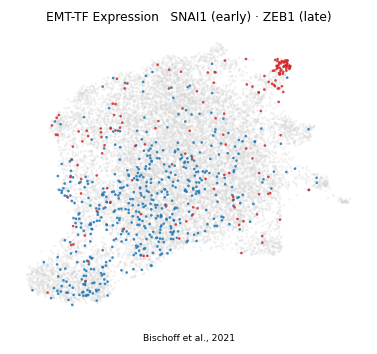

In [5]:
# expression.pdf — early vs late EMT-TF overlay on the 2-D manifold
adata.obsm['X_umap'] = adata.obsm['X_umap']  # native 2-D layout
def _vec(g):
    x = adata[:,g].X
    return x.toarray().ravel() if hasattr(x,'toarray') else np.asarray(x).ravel()
thr = {}
for g in [early_tf, late_tf]:
    v=_vec(g); pos=v[v>0]; thr[g]=float(np.quantile(pos,0.75)) if pos.size else 0.0
sel = {g: _vec(g) > thr[g] for g in [early_tf, late_tf]}
order = sorted([early_tf, late_tf], key=lambda g: -int(sel[g].sum()))
colors = {early_tf:'tab:blue', late_tf:'tab:red'}
fig, ax = plt.subplots(figsize=(4.2,3.4))
sc.pl.umap(adata, size=10, alpha=.3, frameon=False, show=False, ax=ax, na_color='lightgray')
for g in order:
    ap = adata[sel[g]].copy()
    sc.pl.umap(ap, na_color=colors[g], size=12, alpha=.85, frameon=False, show=False, ax=ax)
ax.set_aspect('equal')
ax.set_title(f'EMT-TF Expression   {early_tf} (early) · {late_tf} (late)', size=8)
ax.text(.5,-.08,'Bischoff et al., 2021', ha='center', transform=ax.transAxes, size=6)
fig.savefig(os.path.join(pth_fig,'expression.pdf'), bbox_inches='tight')
plt.show()
for g in [early_tf, late_tf]:
    m=sel[g]; print(f'{g}: {(_vec(g)>0).mean()*100:.1f}%% expressing; {int(m.sum())} shown (upper quartile), mean pseudotime shown = {tn[m].mean():.2f}')
print('saved expression.pdf')